In [25]:
import numpy as np
import matplotlib
%matplotlib inline  
# matplotlib.use("TkAgg")    # or "Qt5Agg" depending on what you have installed
import matplotlib.pyplot as plt
from matplotlib import rcParams
from astropy import units as u
from scipy.stats import norm
import pandas as pd
import scipy.interpolate as si

AU_cm = (1 * u.AU).to(u.cm).value

In [26]:
params = {
   'axes.labelsize': 20,
   'font.size': 20,
   'legend.fontsize': 10,
   'xtick.labelsize': 20,
   'ytick.labelsize': 15,
   #'text.usetex': True, #to use TeX in your labels
   'font.family':'serif',
   'axes.titlesize': 15
   }
rcParams.update(params)

In [27]:
# Load digitized data
ueda_from_paper_df = pd.read_csv("ueda_sigma_grid.csv")

r = ueda_from_paper_df["r"].values
sigma = ueda_from_paper_df["sigma"].values

# Interpolator in log–log space
log_interp = si.interp1d(
    np.log(r),
    np.log(sigma),
    kind="linear",   # straight lines in log–log space
    fill_value="extrapolate"  # allow extrapolation beyond data
)

def ueda_from_paper(r_new):
    """Extrapolated sigma(r) from paper plot (log–log interpolation)."""
    return np.exp(log_interp(np.log(r_new)))

# Example: finer grid
r_fine = np.logspace(np.log10(r.min()), np.log10(r.max()), 100)
sigma_fine = ueda_from_paper(r_fine)


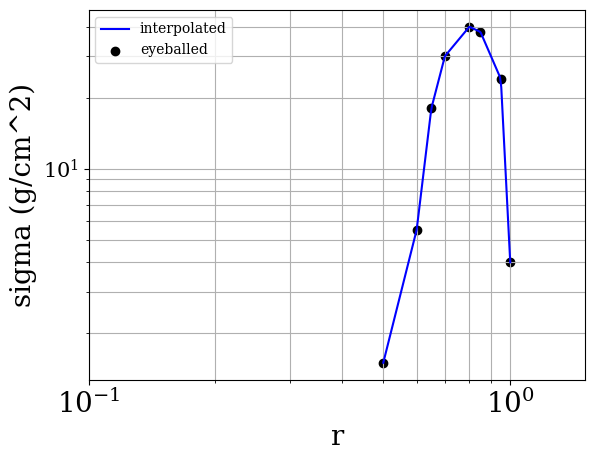

In [28]:
plt.plot(r_fine, sigma_fine, color = 'blue', label = 'interpolated')
plt.scatter(ueda_from_paper_df['r'], ueda_from_paper_df['sigma'], color = 'black', label = 'eyeballed')


plt.grid('True', 'both')

plt.xlim(0.1, 1.5)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("r")
plt.ylabel("sigma (g/cm^2)")
plt.legend()
plt.show()
plt.show()

In [29]:
def sample_from_g(x, y, n_samples=100, random_state=None):
    """
    Sample from distribution g(x) = x * y(x), given arrays x and y.
    
    Parameters
    ----------
    x : array_like
        1D array of x values (must be sorted).
    y : array_like
        1D array of y(x) values, same length as x.
    n_samples : int
        Number of random samples to draw.
    random_state : int or None
        Random seed for reproducibility.
    
    Returns
    -------
    samples : ndarray
        Random samples drawn from g(x).
    """
    rng = np.random.default_rng(random_state)
    
    # Compute g(x)
    g = x * y
    #g[g < 0] = 0  # in case of negatives
    
    # Compute cumulative distribution (CDF)
    cdf = np.cumsum(g)
    cdf = cdf / cdf[-1]  # normalize to 1
    
    # Draw uniform samples in [0,1]
    u = rng.random(n_samples)
    
    # Invert the CDF
    samples = np.interp(u, cdf, x)
    return samples


a_samples = sample_from_g(r_fine, sigma_fine, n_samples=150, random_state=42)

In [30]:
def compute_surface_density(semi_major_axes, m_g, bins=None):
    """
    Estimate Sigma(a) from sampled bodies of equal mass m_g (grams).
    """
    if bins is None:
        bins = np.linspace(0.3, 2.0, 25)
    counts, edges = np.histogram(semi_major_axes, bins=bins)
    r1, r2 = edges[:-1], edges[1:]
    areas = np.pi * ((r2**2 - r1**2) * AU_cm**2)
    sigma = counts * m_g / areas
    centers = 0.5 * (r1 + r2)
    return centers, sigma

n_samples = len(a_samples)
m_pl_ueda = (2.2 * u.M_earth.to(u.g))/n_samples
centers, sigmas_from_a = compute_surface_density(a_samples, m_pl_ueda, bins = np.linspace(0.3, 1.2, 10))

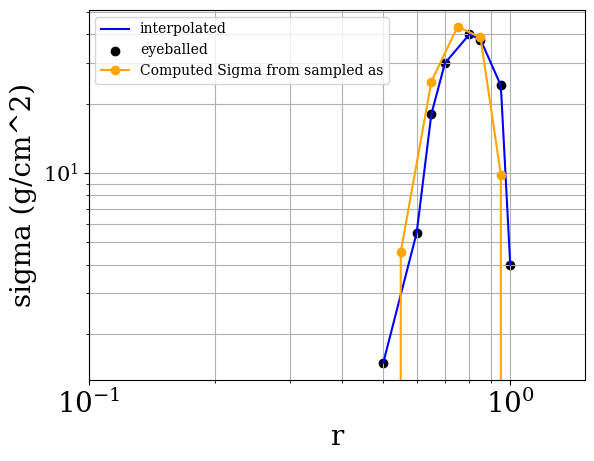

In [31]:
plt.plot(r_fine, sigma_fine, color = 'blue', label = 'interpolated')
plt.scatter(ueda_from_paper_df['r'], ueda_from_paper_df['sigma'], color = 'black', label = 'eyeballed')
plt.plot(centers, sigmas_from_a, color = 'orange', marker='o', label = 'Computed Sigma from sampled as')

plt.grid('True', 'both')

plt.xlim(0.1, 1.5)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("r")
plt.ylabel("sigma (g/cm^2)")
plt.legend()
plt.show()
plt.show()

In [32]:
a_samples_sorted = np.sort(a_samples)
a_samples_sorted

array([0.53757669, 0.58255971, 0.58515992, 0.58537406, 0.60209746,
       0.61805593, 0.62067985, 0.63475838, 0.6390954 , 0.65140303,
       0.65242551, 0.65424922, 0.65561345, 0.65791685, 0.65911688,
       0.66285625, 0.66849337, 0.67020428, 0.67497957, 0.67581906,
       0.68021292, 0.68023281, 0.68225368, 0.68555181, 0.68635427,
       0.6891878 , 0.69143018, 0.69283004, 0.69520175, 0.69987816,
       0.70175015, 0.70365914, 0.70454858, 0.70891104, 0.71325335,
       0.71336913, 0.71570723, 0.72662557, 0.72699704, 0.72876614,
       0.73180614, 0.73410415, 0.73583202, 0.73841317, 0.73920788,
       0.73986195, 0.74192267, 0.74622895, 0.74750542, 0.74804557,
       0.75284874, 0.75523401, 0.75747772, 0.76013138, 0.7602352 ,
       0.76333775, 0.76528968, 0.77093651, 0.77157426, 0.77371225,
       0.77846969, 0.77980573, 0.77993127, 0.78043009, 0.78043963,
       0.78174054, 0.78253277, 0.78344691, 0.78373845, 0.78527249,
       0.78616596, 0.78700876, 0.78838389, 0.78917857, 0.78961

In [33]:
#np.savetxt("semi_major_axes/ueda_2021_as_sep5.txt", a_samples_sorted)

In [34]:
"""a_samples = sample_from_g(r_fine, sigma_fine, n_samples=1000, random_state=42)

n_samples = len(a_samples)
m_pl_ueda = (2.2 * u.M_earth.to(u.g))/n_samples
centers, sigmas_from_a = compute_surface_density(a_samples, m_pl_ueda, bins = np.linspace(0.3, 1.2, 20))

plt.plot(r_fine, sigma_fine, color = 'blue', label = 'interpolated')
plt.scatter(ueda_from_paper_df['r'], ueda_from_paper_df['sigma'], color = 'black', label = 'eyeballed')
plt.plot(centers, sigmas_from_a, color = 'orange', marker='o', label = 'Computed Sigma from sampled as')

plt.grid('True', 'both')

plt.xlim(0.1, 1.5)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("r")
plt.ylabel("sigma (g/cm^2)")
plt.legend()
plt.show()
plt.show()
"""

'a_samples = sample_from_g(r_fine, sigma_fine, n_samples=1000, random_state=42)\n\nn_samples = len(a_samples)\nm_pl_ueda = (2.2 * u.M_earth.to(u.g))/n_samples\ncenters, sigmas_from_a = compute_surface_density(a_samples, m_pl_ueda, bins = np.linspace(0.3, 1.2, 20))\n\nplt.plot(r_fine, sigma_fine, color = \'blue\', label = \'interpolated\')\nplt.scatter(ueda_from_paper_df[\'r\'], ueda_from_paper_df[\'sigma\'], color = \'black\', label = \'eyeballed\')\nplt.plot(centers, sigmas_from_a, color = \'orange\', marker=\'o\', label = \'Computed Sigma from sampled as\')\n\nplt.grid(\'True\', \'both\')\n\nplt.xlim(0.1, 1.5)\n\nplt.xscale("log")\nplt.yscale("log")\nplt.xlabel("r")\nplt.ylabel("sigma (g/cm^2)")\nplt.legend()\nplt.show()\nplt.show()\n'

In [36]:
(len(a_samples) * m_pl_ueda) * u.g.to(u.M_earth)

2.2

In [37]:
np.savetxt("semi_major_axes/ueda_2021_as_sep9.txt", a_samples_sorted)

In [38]:
m_pl_ueda

8.759179539427357e+25

In [40]:
m_pl_ueda * u.g.to(u.M_sun)

4.40511771164783e-08